# **Image restoration and noise handling**

#### **1. Masks**
What is a mask?
- A mask is a binary image (boolean array) that highlights regions of interest (True) and ignores others (False).
- Masks are used to selectively process or analyze parts of an image.

Creating a mask using conditions and `np.where`

In [37]:
import numpy as np
from skimage import data
import matplotlib.pyplot as plt

image = data.coins()


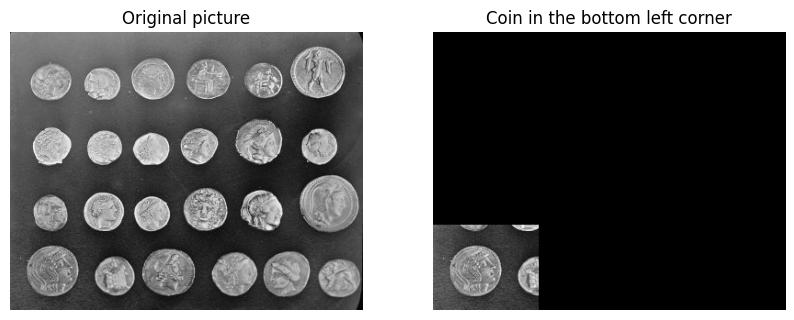

In [38]:
# Rectangle mask to keep only the coin in the bottom left corner
keep_mask = np.zeros_like(image, dtype=bool)
# y coordinates from 210 to 303 and x coordinates from 0 to 115 - correct if needed
keep_mask[210:303, 0:115] = True

# Cover all other coins and background
covered_image = image * keep_mask
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original picture")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(covered_image, cmap="gray")
plt.title("Coin in the bottom left corner")
plt.axis("off")

plt.show()

Applying a mask to an image


In [39]:
# create a mask for pixels brighter than a value (e.g., 130)
mask = image > 130  # boolean mask
print(mask.dtype)
print(image.shape)
print(mask.shape)


bool
(303, 384)
(303, 384)


In [40]:
# using np.where to create a mask with 1s and 0s
mask_numeric = np.where(image > 130, 1, 0)
print(mask_numeric.dtype)
print(mask_numeric.shape)

int64
(303, 384)


uint8
(303, 384)


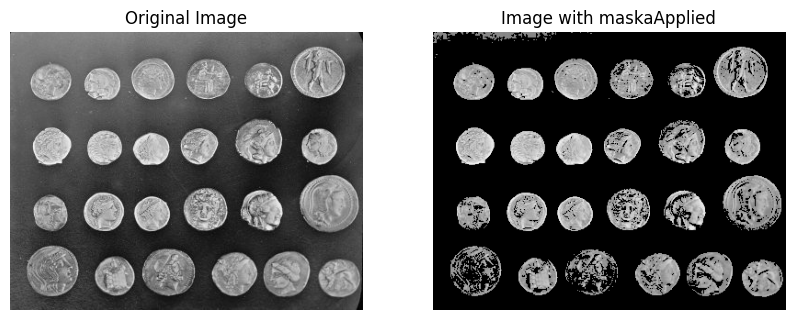

In [41]:
# set all pixels outside the mask to zero (black)
masked_image = image * mask
print(masked_image.dtype)
print(masked_image.shape)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image, cmap='gray')
axes[0].set_title("Original Image")
axes[0].axis('off')

axes[1].imshow(masked_image, cmap='gray')
axes[1].set_title("Image with maskaApplied")
axes[1].axis('off')
plt.show()


#### **2. Image restoration**

Image restoration involves techniques to recover or reconstruct parts of an image that are damaged, missing, or corrupted. One effective approach is inpainting, which fills in missing areas naturally based on surrounding pixels.

In [42]:
from skimage.restoration import inpaint
from skimage import io

image = io.imread("nature.jpg")

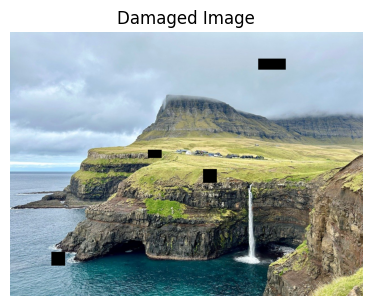

In [43]:
# simulate damage by zeroing out a rectangular region
mask = np.zeros(image.shape, dtype=bool)
mask[500:550, 700:750] = True  # mark area to inpaint
mask[430:460, 500:550] = True
mask[100:140, 900:1000] = True
mask[800:850, 150:200] = True

damaged = image.copy()
damaged[mask] = 0  # remove pixels in mask region

plt.figure(figsize=(10,4))
plt.subplot(1, 2, 1)
plt.imshow(damaged, cmap='gray')
plt.title('Damaged Image')
plt.axis('off')
plt.show()

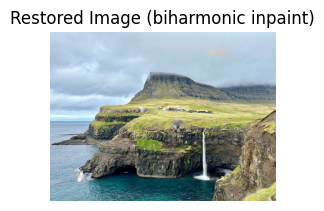

In [44]:
restored = inpaint.inpaint_biharmonic(damaged, mask, channel_axis=None)

plt.subplot(1, 2, 2)
plt.imshow(restored, cmap='gray')
plt.title('Restored Image (biharmonic inpaint)')
plt.axis('off')
plt.show()


- The method fills in the masked region smoothly using PDE-based interpolation.
- Works well for small to medium regions with smooth textures.
- Inpainting is not magic: large missing areas or complex textures can be challenging.

#### **3. Noise simulation in images**
- Simulating noise helps test denoising algorithms or understand noise effects.
- Use `skimage.util.random_noise` to add various noise types, like Gaussian, salt & pepper, speckle.

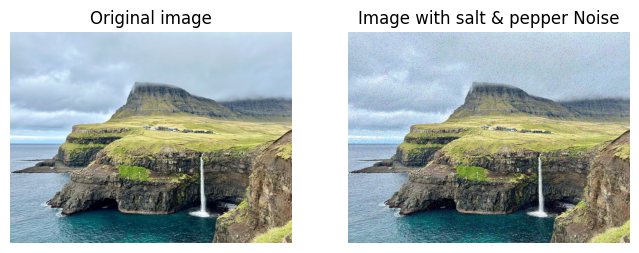

In [45]:
from skimage.util import random_noise

noisy_image = random_noise(image, mode='s&p', amount=0.05)  # salt & pepper noise

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title("Original image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(noisy_image, cmap='gray')
plt.title("Image with salt & pepper Noise")
plt.axis('off')
plt.show()


#### **4. Denoising**
`denoise_tv_chambolle` reduces noise by minimizing the total variation of the image. It effectively smooths out noise in flat regions while preserving sharp edges.

- `weight` controls the denoising strength (higher values mean stronger smoothing).

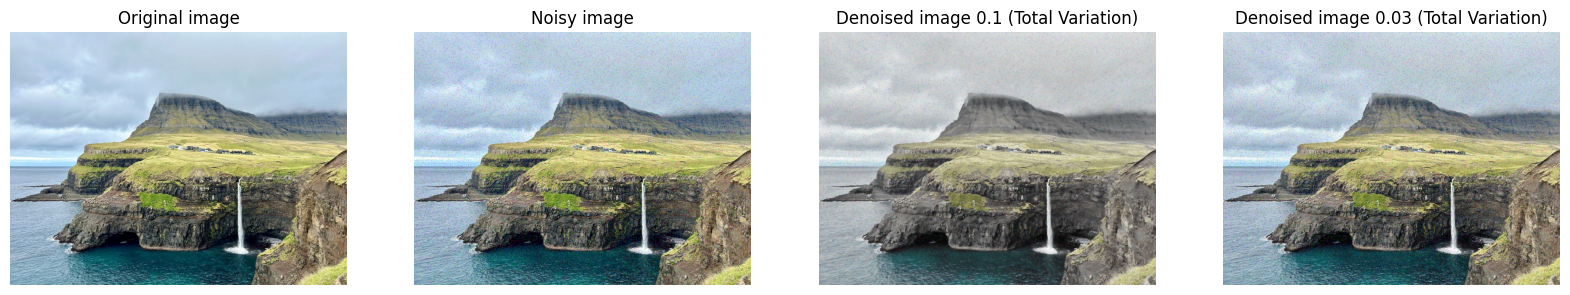

In [46]:
from skimage.restoration import denoise_tv_chambolle
import matplotlib.pyplot as plt

tv_denoised_1 = denoise_tv_chambolle(noisy_image, weight=0.1, channel_axis=None)
tv_denoised_03 = denoise_tv_chambolle(noisy_image, weight=0.03)


plt.figure(figsize=(20, 5))
plt.subplot(1, 4, 1)
plt.imshow(image, cmap='gray')
plt.title('Original image')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(noisy_image, cmap='gray')
plt.title('Noisy image')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(tv_denoised_1, cmap='gray')
plt.title('Denoised image 0.1 (Total Variation)')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(tv_denoised_03, cmap='gray')
plt.title('Denoised image 0.03 (Total Variation)')
plt.axis('off')


plt.show()
